In [1]:
from pathlib import Path
import geopandas as gpd
caminho = Path("../dados/brutos/populacao/BA_setores_CD2022.gpkg")
print(Path.exists(caminho))



True


In [2]:
setores =  gpd.read_file(caminho)
setores.head()

,CD_SETOR,SITUACAO,CD_SIT,CD_TIPO,AREA_KM2,CD_REGIAO,NM_REGIAO,CD_UF,NM_UF,CD_MUN,...,CD_CONCURB,NM_CONCURB,v0001,v0002,v0003,v0004,v0005,v0006,v0007,geometry
0,290010805000001,Urbana,2,0,1.252312,2,Nordeste,29,Bahia,2900108,...,.,None,807,421,419,2,2.7,0.0000,296,"POLYGON ((-41.65404 -13.25992, -41.65429 -13.2..."
1,290010805000002,Urbana,1,0,0.258088,2,Nordeste,29,Bahia,2900108,...,.,None,416,234,234,0,2.5,0.1183,169,"POLYGON ((-41.66355 -13.25025, -41.66324 -13.2..."
2,290010805000003,Urbana,1,0,0.147805,2,Nordeste,29,Bahia,2900108,...,.,None,681,392,392,0,2.5,0.0519,270,"POLYGON ((-41.66835 -13.25551, -41.66944 -13.2..."
3,290010805000004,Urbana,2,0,0.735364,2,Nordeste,29,Bahia,2900108,...,.,None,617,341,341,0,2.6,0.0212,236,"POLYGON ((-41.65836 -13.2428, -41.65825 -13.24..."
4,290010805000005,Urbana,2,0,0.514993,2,Nordeste,29,Bahia,2900108,...,.,None,235,138,138,0,2.8,0.0118,85,"POLYGON ((-41.66086 -13.24759, -41.65664 -13.2..."


In [3]:
print("Dimensões:", setores.shape)
print("CRS:", setores.crs)
print("Colunas:", setores.columns.tolist())

Dimensões: (31070, 37)
CRS: EPSG:4674
Colunas: ['CD_SETOR', 'SITUACAO', 'CD_SIT', 'CD_TIPO', 'AREA_KM2', 'CD_REGIAO', 'NM_REGIAO', 'CD_UF', 'NM_UF', 'CD_MUN', 'NM_MUN', 'CD_DIST', 'NM_DIST', 'CD_SUBDIST', 'NM_SUBDIST', 'CD_BAIRRO', 'NM_BAIRRO', 'CD_NU', 'NM_NU', 'CD_FCU', 'NM_FCU', 'CD_AGLOM', 'NM_AGLOM', 'CD_RGINT', 'NM_RGINT', 'CD_RGI', 'NM_RGI', 'CD_CONCURB', 'NM_CONCURB', 'v0001', 'v0002', 'v0003', 'v0004', 'v0005', 'v0006', 'v0007', 'geometry']


In [4]:
setores_salvador = setores.loc[
    setores["NM_MUN"] == "Salvador"
].copy()

print("Setores de Salvador:", len(setores_salvador))

print(
    setores_salvador[["CD_MUN", "NM_MUN"]]
    .drop_duplicates()
    .to_string(index=False)
)

Setores de Salvador: 4545
 CD_MUN   NM_MUN
2927408 Salvador


In [5]:
print("Códigos ausentes:", setores_salvador["CD_SETOR"].isna().sum())
print("Códigos duplicados:", setores_salvador["CD_SETOR"].duplicated().sum())

print("Geometrias ausentes:", setores_salvador.geometry.isna().sum())
print("Geometrias vazias:", setores_salvador.geometry.is_empty.sum())
print("Geometrias inválidas:", (~setores_salvador.geometry.is_valid).sum())

Códigos ausentes: 0
Códigos duplicados: 3
Geometrias ausentes: 0
Geometrias vazias: 0
Geometrias inválidas: 0


In [6]:
duplicados = setores_salvador.loc[
    setores_salvador["CD_SETOR"].duplicated(keep=False)
].sort_values("CD_SETOR")

print("Linhas envolvidas:", len(duplicados))
print("Códigos distintos repetidos:", duplicados["CD_SETOR"].nunique())

print(
    duplicados[
        ["CD_SETOR", "NM_BAIRRO", "AREA_KM2", "v0001", "v0002"]
    ].to_string(index=False)
)

Linhas envolvidas: 5
Códigos distintos repetidos: 2
       CD_SETOR                               NM_BAIRRO  AREA_KM2  v0001  v0002
292740805100005               Ilha Bom Jesus dos Passos  0.342705    832    558
292740805100005               Ilha Bom Jesus dos Passos  0.342705    832    558
292740805100012 Ilha dos Frades / Ilha de Santo Antônio  6.940856      4     25
292740805100012 Ilha dos Frades / Ilha de Santo Antônio  6.940856      4     25
292740805100012 Ilha dos Frades / Ilha de Santo Antônio  6.940856      4     25


In [7]:
for codigo, grupo in duplicados.groupby("CD_SETOR"):
    atributos = grupo.drop(columns="geometry")

    atributos_iguais = len(atributos.drop_duplicates()) == 1

    geometria_referencia = grupo.geometry.iloc[0]
    geometrias_iguais = all(
        geometria_referencia.equals(geometria)
        for geometria in grupo.geometry
    )

    print("Setor:", codigo)
    print("Todos os atributos iguais:", atributos_iguais)
    print("Geometrias equivalentes:", geometrias_iguais)
    print()

Setor: 292740805100005
Todos os atributos iguais: True
Geometrias equivalentes: False

Setor: 292740805100012
Todos os atributos iguais: True
Geometrias equivalentes: False



In [8]:
duplicados_utm = duplicados.to_crs(epsg=31984)

for codigo, grupo in duplicados_utm.groupby("CD_SETOR"):
    soma_areas = grupo.geometry.area.sum()
    area_uniao = grupo.geometry.union_all().area

    print("Setor:", codigo)
    print(f"Soma das áreas: {soma_areas:.2f} m²")
    print(f"Área da união: {area_uniao:.2f} m²")
    print(f"Diferença: {soma_areas - area_uniao:.2f} m²")
    print()

Setor: 292740805100005
Soma das áreas: 342443.35 m²
Área da união: 342443.35 m²
Diferença: 0.00 m²

Setor: 292740805100012
Soma das áreas: 6935570.33 m²
Área da união: 6935570.33 m²
Diferença: 0.00 m²



In [9]:
setores_salvador_unicos = setores_salvador.dissolve(
    by="CD_SETOR",
    aggfunc="first",
    as_index=False
)

In [10]:
print("Registros:", len(setores_salvador_unicos))
print(
    "Códigos duplicados:",
    setores_salvador_unicos["CD_SETOR"].duplicated().sum()
)
print(
    "Geometrias inválidas:",
    (~setores_salvador_unicos.geometry.is_valid).sum()
)

Registros: 4542
Códigos duplicados: 0
Geometrias inválidas: 0


In [11]:
populacao = setores_salvador_unicos["v0001"]

print("Tipo:", populacao.dtype)
print("Valores ausentes:", populacao.isna().sum())
print(populacao.head(10))

Tipo: int64
Valores ausentes: 0
0    463
1    334
2    332
3    153
4    481
5    781
6     33
7    645
8    803
9    499
Name: v0001, dtype: int64


In [12]:
print("População total:", setores_salvador_unicos["v0001"].sum())
print(
    "Setores com população negativa:",
    (setores_salvador_unicos["v0001"] < 0).sum()
)
print(
    "Setores com população zero:",
    (setores_salvador_unicos["v0001"] == 0).sum()
)

População total: 2417678
Setores com população negativa: 0
Setores com população zero: 38


In [13]:
setores_salvador_utm = setores_salvador_unicos.to_crs(epsg=31984)

print("CRS:", setores_salvador_utm.crs)
print("Registros:", len(setores_salvador_utm))

CRS: EPSG:31984
Registros: 4542


In [14]:
caminho_pref = Path("../dados/brutos/bairros/prefeitura_bairro.gpkg")
#print(Path.exists(caminho_pref))
pref_bairro = gpd.read_file(caminho_pref)
#pref_bairro.head()
piloto = pref_bairro.loc[
    pref_bairro["COD_PBR"] == "I"
].copy()

limite_piloto = piloto.geometry.iloc[0]


/home/emanu/projetos/ftl-projeto-final/.venv/lib/python3.10/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'prefeitura_bairro.gpkg': 'prefeituras_bairro_a' (default), 'layer_styles'. Specify layer parameter to avoid this warning.
  result = read_func(


In [15]:
setores_candidatos = setores_salvador_utm.loc[
    setores_salvador_utm.geometry.intersects(limite_piloto)
].copy()

print("Setores candidatos:", len(setores_candidatos))

Setores candidatos: 566


In [16]:
setores_candidatos["area_setor_m2"] = (
    setores_candidatos.geometry.area
)

setores_candidatos["area_no_piloto_m2"] = (
    setores_candidatos.geometry
    .intersection(limite_piloto)
    .area
)

setores_candidatos["percentual_no_piloto"] = (
    setores_candidatos["area_no_piloto_m2"]
    / setores_candidatos["area_setor_m2"]
) * 100

In [17]:
print(
    "Contatos sem área:",
    (setores_candidatos["area_no_piloto_m2"] == 0).sum()
)

print(
    setores_candidatos["percentual_no_piloto"]
    .describe()
)

Contatos sem área: 0
count    566.000000
mean      92.445022
std       25.569886
min        0.003435
25%      100.000000
50%      100.000000
75%      100.000000
max      100.000000
Name: percentual_no_piloto, dtype: float64


In [18]:
parciais = setores_candidatos.loc[
    (setores_candidatos["percentual_no_piloto"] > 1)
    & (setores_candidatos["percentual_no_piloto"] < 99)
]

print("Setores entre 1% e 99%:", len(parciais))

print(
    parciais[["CD_SETOR", "v0001", "percentual_no_piloto"]]
    .sort_values("percentual_no_piloto")
    .to_string(index=False, float_format=lambda valor: f"{valor:.4f}")
)

Setores entre 1% e 99%: 46
       CD_SETOR  v0001  percentual_no_piloto
292740805270342    235                1.0543
292740805270108    510                1.2151
292740805270105    516                1.2511
292740805270335    425                1.4217
292740805270251    215                1.8255
292740805270381    945                2.4129
292740805270102    600                2.6201
292740805270336    303                3.2980
292740805270113    316                3.4164
292740805210305    206                3.8627
292740805210291     73                4.0011
292740805270111    552                4.9536
292740805270090    477                7.8628
292740805270154    459                8.1346
292740805270038    205                8.4680
292740805210232    506               69.6110
292740805210274    117               70.4301
292740805270375    560               79.1461
292740805210049    511               80.4657
292740805170001    582               80.6609
292740805270374    352      

In [19]:
setores_candidatos["pop_estimada_no_piloto"] = (
    setores_candidatos["v0001"]
    * setores_candidatos["area_no_piloto_m2"]
    / setores_candidatos["area_setor_m2"]
)

print(
    "População estimada no piloto:",
    f"{setores_candidatos['pop_estimada_no_piloto'].sum():,.2f}"
)

População estimada no piloto: 238,643.08


In [20]:
caminho_grade = Path(
    "../dados/processados/centro_brotas_h3_res10.gpkg"
)

grade = gpd.read_file(
    caminho_grade,
    layer="grade_recortada"
)

print("Células:", len(grade))
print("CRS:", grade.crs)

Células: 1145
CRS: EPSG:31984


In [21]:
fragmentos = gpd.overlay(
    setores_candidatos[
        ["CD_SETOR", "v0001", "area_setor_m2", "geometry"]
    ],
    grade[["h3_id", "geometry"]],
    how="intersection",
    keep_geom_type=True
)

print("Fragmentos:", len(fragmentos))
fragmentos.head()

Fragmentos: 3694


,CD_SETOR,v0001,area_setor_m2,h3_id,geometry
0,292740805060008,33,31685.507865,8a8116b032a7fff,"POLYGON ((555713.603 8562204.118, 555726.222 8..."
1,292740805060008,33,31685.507865,8a8116b032b7fff,"MULTIPOLYGON (((555749.267 8562197.2, 555752.1..."
2,292740805070001,758,40310.326562,8a8116b0ad87fff,"POLYGON ((554834.671 8564373.684, 554840.512 8..."
3,292740805070001,758,40310.326562,8a8116b0ad97fff,"POLYGON ((554846.237 8564365.411, 554843.666 8..."
4,292740805070001,758,40310.326562,8a8116b0adb7fff,"POLYGON ((554875.602 8564347.183, 554858.782 8..."


In [22]:
fragmentos["area_fragmento_m2"] = fragmentos.geometry.area

fragmentos["pop_estimada"] = (
    fragmentos["v0001"]
    * fragmentos["area_fragmento_m2"]
    / fragmentos["area_setor_m2"]
)

In [23]:
total_piloto = setores_candidatos["pop_estimada_no_piloto"].sum()
total_fragmentos = fragmentos["pop_estimada"].sum()

print(f"Estimativa do piloto: {total_piloto:.6f}")
print(f"Soma dos fragmentos: {total_fragmentos:.6f}")
print(f"Diferença: {total_fragmentos - total_piloto:.6f}")

Estimativa do piloto: 238643.078117
Soma dos fragmentos: 238643.078117
Diferença: 0.000000


In [24]:
pop_por_celula = (
    fragmentos.groupby("h3_id", as_index=False)["pop_estimada"]
    .sum()
)

In [25]:
grade_populacao = grade.merge(
    pop_por_celula,
    on="h3_id",
    how="left",
    validate="one_to_one"
)

In [26]:
print("Células:", len(grade_populacao))
print(
    "Células sem estimativa:",
    grade_populacao["pop_estimada"].isna().sum()
)
print(
    "População total estimada:",
    grade_populacao["pop_estimada"].sum()
)

Células: 1145
Células sem estimativa: 0
População total estimada: 238643.07811679516


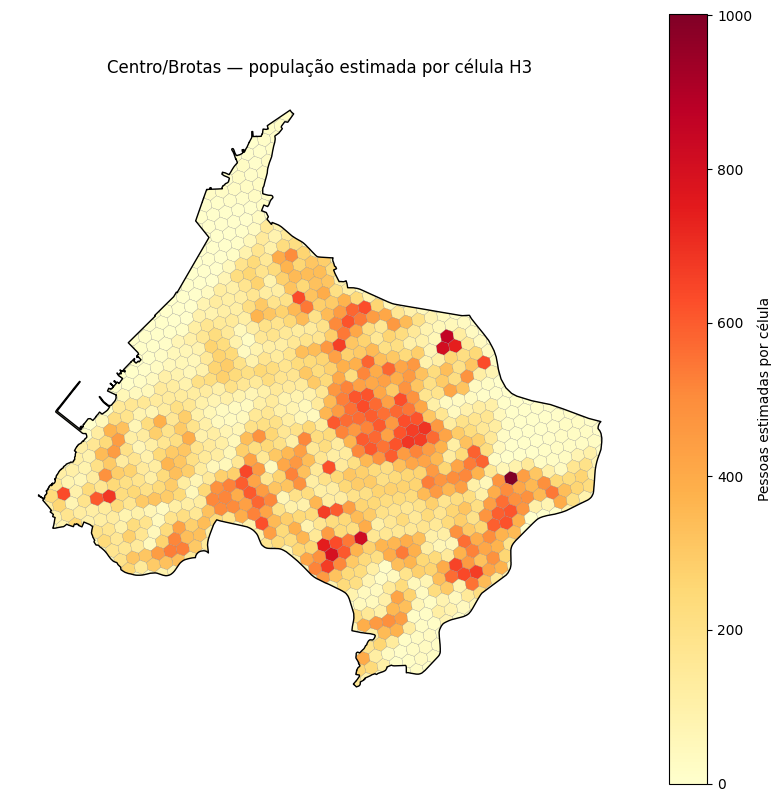

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

grade_populacao.plot(
    column="pop_estimada",
    ax=ax,
    cmap="YlOrRd",
    legend=True,
    edgecolor="gray",
    linewidth=0.15,
    legend_kwds={"label": "Pessoas estimadas por célula"}
)

piloto.boundary.plot(ax=ax, color="black", linewidth=1)

ax.set_title("Centro/Brotas — população estimada por célula H3")
ax.set_axis_off()

plt.show()

In [28]:
print(grade_populacao["pop_estimada"].describe())

print(
    "Células com estimativa zero:",
    (grade_populacao["pop_estimada"] == 0).sum()
)

count    1145.000000
mean      208.421902
std       181.216573
min         0.000000
25%        51.504651
50%       169.057871
75%       314.600985
max      1002.575220
Name: pop_estimada, dtype: float64
Células com estimativa zero: 13


In [29]:
print(grade_populacao["pop_estimada"].describe())

print(
    "Células com estimativa zero:",
    (grade_populacao["pop_estimada"] == 0).sum()
)

count    1145.000000
mean      208.421902
std       181.216573
min         0.000000
25%        51.504651
50%       169.057871
75%       314.600985
max      1002.575220
Name: pop_estimada, dtype: float64
Células com estimativa zero: 13


In [30]:
arquivo_populacao = Path(
    "../dados/processados/centro_brotas_h3_res10_populacao.gpkg"
)

grade_populacao.to_file(
    arquivo_populacao,
    layer="populacao_estimada",
    driver="GPKG",
    index=False
)

In [31]:
conferencia = gpd.read_file(
    arquivo_populacao,
    layer="populacao_estimada"
)

print("Células:", len(conferencia))
print("CRS:", conferencia.crs)
print(f"População estimada: {conferencia['pop_estimada'].sum():.6f}")

Células: 1145
CRS: EPSG:31984
População estimada: 238643.078117
